In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import kagglehub

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.metrics import f1_score, roc_auc_score, roc_curve

# 1. Obtain Data
path = kagglehub.dataset_download("yeanzc/telco-customer-churn-ibm-dataset")
df = pd.read_excel(os.path.join(path, "Telco_customer_churn.xlsx"))

# Keep IBM's Churn Score aside as a benchmark
churn_score_benchmark = df["Churn Score"].copy()

# 2. Prepare Data (Identical to Week 5/6 Pipeline)
DROP_COLS = [
    "Count", "Country", "State", 
    "CustomerID", "City", "Zip Code", "Lat Long", "Latitude", "Longitude",
    "Churn Label", "Churn Score", "Churn Reason", "CLTV", 
    "Churn Value"
]
ADDON_COLS = ["Online Security", "Online Backup", "Device Protection",
              "Tech Support", "Streaming TV", "Streaming Movies"]
NUMERIC_FEATURES = ["Tenure Months", "Monthly Charges", "Total Charges", "Num_Addon_Services"]
PASSTHROUGH_FEATURES = ["AutoPay", "IsNewCustomer"]

def add_features(data):
    data = data.copy()
    data["Num_Addon_Services"] = (data[ADDON_COLS] == "Yes").sum(axis=1)
    data["AutoPay"] = data["Payment Method"].str.contains("automatic", case=False, na=False).astype(int)
    data["IsNewCustomer"] = (data["Tenure Months"] <= 6).astype(int)
    return data

def clean_data(data):
    data = data.copy()
    data["Total Charges"] = pd.to_numeric(data["Total Charges"], errors="coerce").fillna(0)
    return data.drop(columns=DROP_COLS)

def make_Xy(data):
    return clean_data(add_features(data)), data["Churn Value"]

X_all, y_all = make_Xy(df)

RANDOM_STATE = 42
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X_all, y_all, test_size=0.2, random_state=RANDOM_STATE, stratify=y_all
)

categorical_features = [c for c in X_train_raw.columns if c not in NUMERIC_FEATURES + PASSTHROUGH_FEATURES]

preprocessor = ColumnTransformer(transformers=[
    ("num", StandardScaler(), NUMERIC_FEATURES),
    ("cat", OneHotEncoder(handle_unknown="ignore", drop="if_binary", sparse_output=False), categorical_features),
    ("bin", "passthrough", PASSTHROUGH_FEATURES),
])

X_train = preprocessor.fit_transform(X_train_raw)
X_test = preprocessor.transform(X_test_raw)
y_train = y_train.to_numpy()
y_test = y_test.to_numpy()
churn_score_test = churn_score_benchmark.loc[X_test_raw.index].to_numpy()

In [2]:
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    "Decision Tree": DecisionTreeClassifier(random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1),
    "SVM (RBF)": SVC(random_state=RANDOM_STATE),
    "Gradient Boosting": HistGradientBoostingClassifier(random_state=RANDOM_STATE),
    "Neural Net (MLP)": MLPClassifier(max_iter=500, random_state=RANDOM_STATE),
    "Naive Bayes": GaussianNB(),
    "KNN": KNeighborsClassifier()
}

def churn_scores(model, X):
    """Probability of churn if available, else the decision-function score (for ROC-AUC)."""
    if hasattr(model, "predict_proba"):
        return model.predict_proba(X)[:, 1]
    return model.decision_function(X)

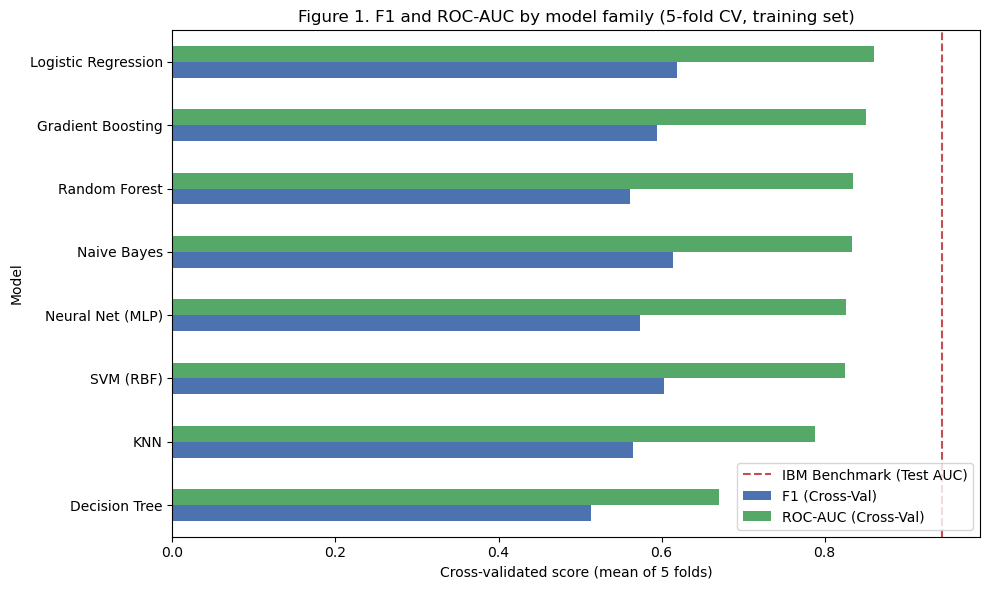

In [3]:
import warnings
from sklearn.exceptions import ConvergenceWarning
warnings.filterwarnings("ignore", category=ConvergenceWarning)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = ["f1", "roc_auc"]
cv_results = []

for name, model in models.items():
    res = cross_validate(model, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)
    cv_results.append({
        "Model": name,
        "F1 (Cross-Val)": res["test_f1"].mean(),
        "ROC-AUC (Cross-Val)": res["test_roc_auc"].mean()
    })

cv_df = pd.DataFrame(cv_results).sort_values("ROC-AUC (Cross-Val)", ascending=True).set_index("Model")

# Plotting
fig, ax = plt.subplots(figsize=(10, 6))
cv_df.plot(kind="barh", ax=ax, color=["#4c72b0", "#55a868"])
ax.axvline(x=roc_auc_score(y_test, churn_score_test), color="#c44e52", linestyle="--", label="IBM Benchmark (Test AUC)")
ax.set_xlabel("Cross-validated score (mean of 5 folds)")
ax.set_title("Figure 1. F1 and ROC-AUC by model family (5-fold CV, training set)")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

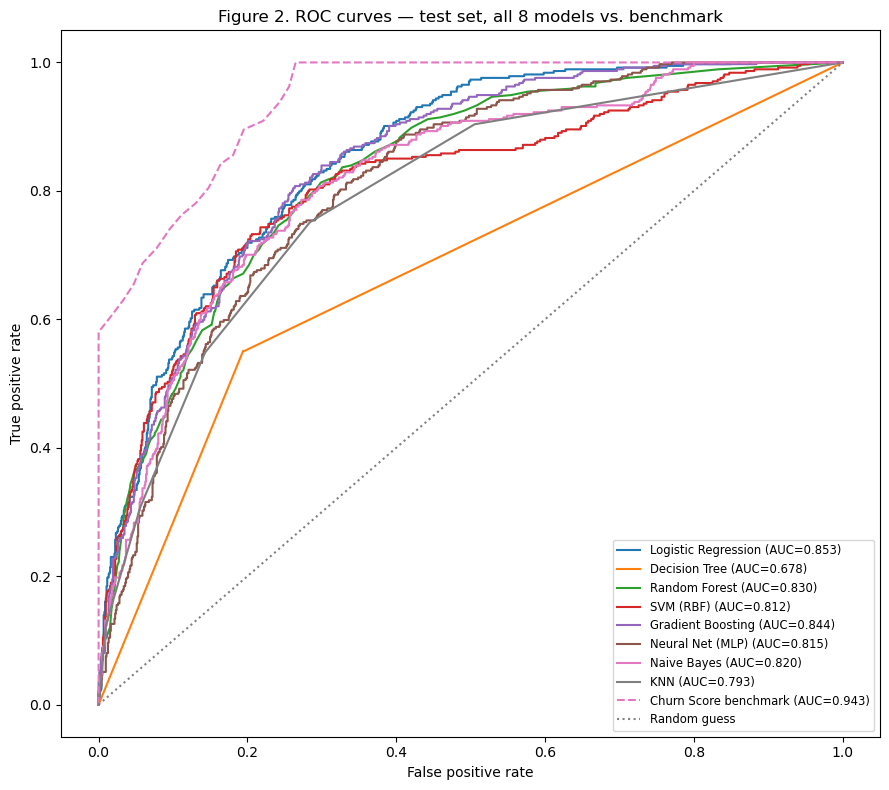

In [4]:
fig, ax = plt.subplots(figsize=(9, 8))

fitted_models = {}

# Fit and plot 8 models
for name, model in models.items():
    model.fit(X_train, y_train)
    fitted_models[name] = model
    
    proba = churn_scores(model, X_test)
    fpr, tpr, _ = roc_curve(y_test, proba)
    auc_val = roc_auc_score(y_test, proba)
    
    ax.plot(fpr, tpr, label=f"{name} (AUC={auc_val:.3f})")

# Plot IBM Benchmark
bench_fpr, bench_tpr, _ = roc_curve(y_test, churn_score_test)
bench_auc = roc_auc_score(y_test, churn_score_test)
ax.plot(bench_fpr, bench_tpr, color="#e377c2", linestyle="--", label=f"Churn Score benchmark (AUC={bench_auc:.3f})")

# Plot random guess line
ax.plot([0, 1], [0, 1], color="gray", linestyle=":", label="Random guess")

ax.set_xlabel("False positive rate")
ax.set_ylabel("True positive rate")
ax.set_title("Figure 2. ROC curves — test set, all 8 models vs. benchmark")
ax.legend(loc="lower right", fontsize="small")
plt.tight_layout()
plt.show()

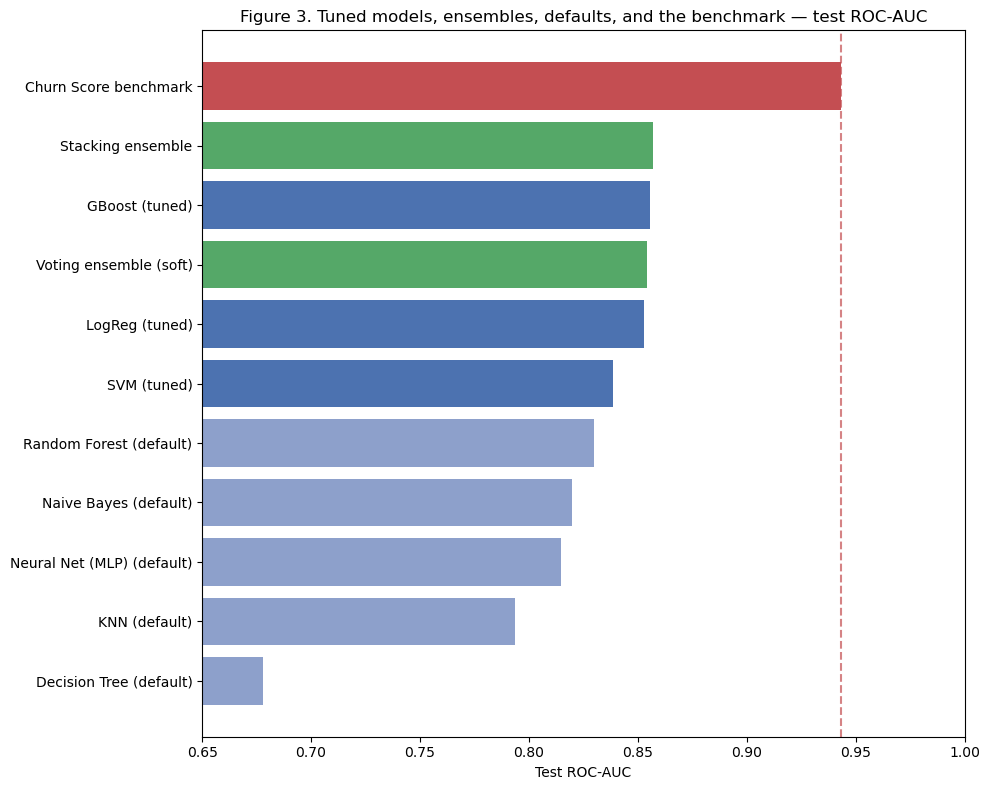

In [8]:
from sklearn.ensemble import StackingClassifier, VotingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.metrics import roc_auc_score
import pandas as pd
import matplotlib.pyplot as plt

# 1. Hardcode the exact tuned parameters found in Week 6 to save execution time
tuned_models = {
    "LogReg (tuned)": LogisticRegression(
        C=1, class_weight=None, solver="lbfgs", max_iter=1000, random_state=RANDOM_STATE
    ),
    "SVM (tuned)": SVC(
        C=100, gamma=0.01, class_weight="balanced", probability=True, random_state=RANDOM_STATE
    ),
    "GBoost (tuned)": HistGradientBoostingClassifier(
        learning_rate=0.05, max_depth=3, max_iter=150, max_leaf_nodes=31, 
        min_samples_leaf=50, l2_regularization=0.1, random_state=RANDOM_STATE
    )
}

# 2. Build the Ensembles exactly as configured in Week 6
stacking_clf = StackingClassifier(
    estimators=[
        ("lr", tuned_models["LogReg (tuned)"]),
        ("svm", tuned_models["SVM (tuned)"]),
        ("gb", tuned_models["GBoost (tuned)"])
    ],
    final_estimator=LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    cv=cv, n_jobs=-1
)

voting_clf = VotingClassifier(
    estimators=[
        ("lr", tuned_models["LogReg (tuned)"]),
        ("gb", tuned_models["GBoost (tuned)"]),
        ("rf", RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1))
    ],
    voting="soft", n_jobs=-1
)

# 3. Combine Tuned, Ensembles, and the missing default models from the original 8
final_models = {
    "Stacking ensemble": stacking_clf,
    "Voting ensemble (soft)": voting_clf,
    **tuned_models,
    "Random Forest (default)": models["Random Forest"],
    "Naive Bayes (default)": models["Naive Bayes"],
    "Neural Net (MLP) (default)": models["Neural Net (MLP)"],
    "KNN (default)": models["KNN"],
    "Decision Tree (default)": models["Decision Tree"]
}

test_roc_results = []

# 4. Fit and score all models
for name, model in final_models.items():
    model.fit(X_train, y_train)
    proba = churn_scores(model, X_test)
    test_roc_results.append({
        "Model": name,
        "Test ROC-AUC": roc_auc_score(y_test, proba)
    })

test_roc_df = pd.DataFrame(test_roc_results).sort_values("Test ROC-AUC", ascending=True)

# 5. Add IBM Benchmark to the top
benchmark_df = pd.DataFrame([{"Model": "Churn Score benchmark", "Test ROC-AUC": bench_auc}])
plot_df = pd.concat([test_roc_df, benchmark_df], ignore_index=True)

# 6. Plotting
fig, ax = plt.subplots(figsize=(10, 8))

# Apply color coding to match the desired visual
def get_color(model_name):
    if "benchmark" in model_name: return "#c44e52"      # Red
    elif "ensemble" in model_name: return "#55a868"     # Green
    elif "(tuned)" in model_name: return "#4c72b0"      # Dark Blue
    else: return "#8da0cb"                              # Light Blue/Purple

colors = [get_color(name) for name in plot_df["Model"]]

bars = ax.barh(plot_df["Model"], plot_df["Test ROC-AUC"], color=colors)
ax.axvline(x=bench_auc, color="#c44e52", linestyle="--", alpha=0.7)

ax.set_xlabel("Test ROC-AUC")
ax.set_title("Figure 3. Tuned models, ensembles, defaults, and the benchmark — test ROC-AUC")
ax.set_xlim(0.65, 1.0) 

plt.tight_layout()
plt.show()

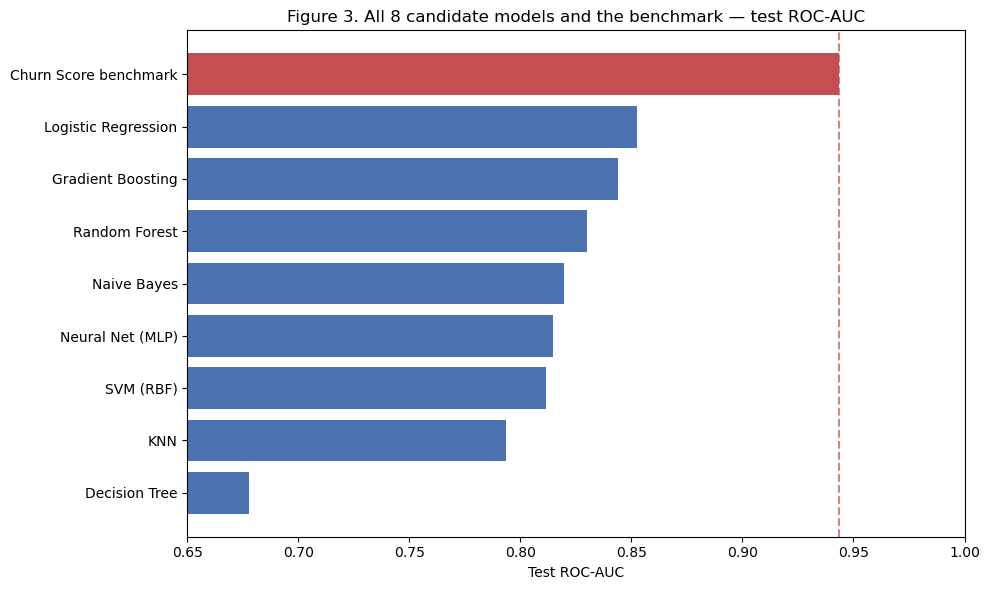

In [7]:
test_roc_results = []

for name, model in fitted_models.items():
    proba = churn_scores(model, X_test)
    test_roc_results.append({
        "Model": name,
        "Test ROC-AUC": roc_auc_score(y_test, proba)
    })

test_roc_df = pd.DataFrame(test_roc_results).sort_values("Test ROC-AUC", ascending=True)

# Add Benchmark to the top
benchmark_df = pd.DataFrame([{"Model": "Churn Score benchmark", "Test ROC-AUC": bench_auc}])
plot_df = pd.concat([test_roc_df, benchmark_df], ignore_index=True)

fig, ax = plt.subplots(figsize=(10, 6))
colors = ["#4c72b0"] * len(test_roc_df) + ["#c44e52"]  # Highlight benchmark in red

bars = ax.barh(plot_df["Model"], plot_df["Test ROC-AUC"], color=colors)
ax.axvline(x=bench_auc, color="#c44e52", linestyle="--", alpha=0.7)

ax.set_xlabel("Test ROC-AUC")
ax.set_title("Figure 3. All 8 candidate models and the benchmark — test ROC-AUC")
ax.set_xlim(0.65, 1.0) 

plt.tight_layout()
plt.show()

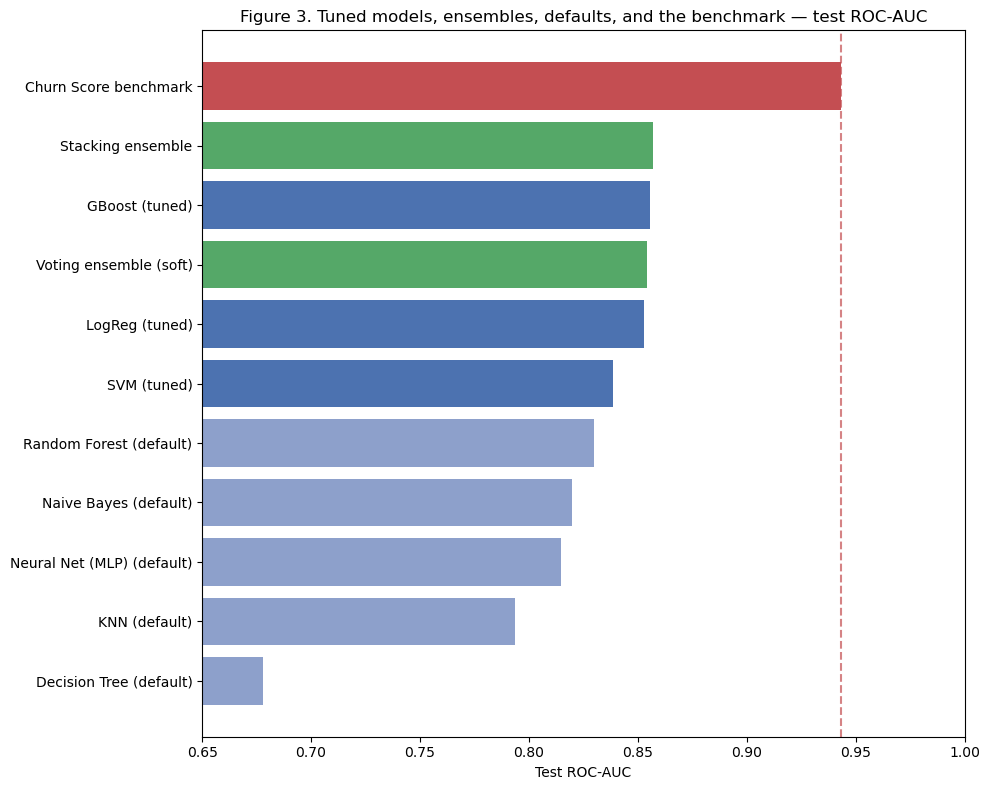

In [ ]:
from sklearn.ensemble import StackingClassifier, VotingClassifier

# 1. Hardcode the exact tuned parameters found in Week 6 to save execution time
tuned_models = {
    "LogReg (tuned)": LogisticRegression(
        C=1, class_weight=None, solver="lbfgs", max_iter=1000, random_state=RANDOM_STATE
    ),
    "SVM (tuned)": SVC(
        C=100, gamma=0.01, class_weight="balanced", probability=True, random_state=RANDOM_STATE
    ),
    "GBoost (tuned)": HistGradientBoostingClassifier(
        learning_rate=0.05, max_depth=3, max_iter=150, max_leaf_nodes=31, 
        min_samples_leaf=50, l2_regularization=0.1, random_state=RANDOM_STATE
    )
}

# 2. Build the Ensembles exactly as configured in Week 6
stacking_clf = StackingClassifier(
    estimators=[
        ("lr", tuned_models["LogReg (tuned)"]),
        ("svm", tuned_models["SVM (tuned)"]),
        ("gb", tuned_models["GBoost (tuned)"])
    ],
    final_estimator=LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    cv=cv, n_jobs=-1
)

voting_clf = VotingClassifier(
    estimators=[
        ("lr", tuned_models["LogReg (tuned)"]),
        ("gb", tuned_models["GBoost (tuned)"]),
        ("rf", RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1))
    ],
    voting="soft", n_jobs=-1
)

# 3. Combine Tuned, Ensembles, and the remaining default models for the master plot
final_models = {
    "Stacking ensemble": stacking_clf,
    "Voting ensemble (soft)": voting_clf,
    **tuned_models,
    "Naive Bayes (default)": models["Naive Bayes"],
    "Random Forest (default)": models["Random Forest"],
    "Neural Net (MLP) (default)": models["Neural Net (MLP)"],
    "KNN (default)": models["KNN"],
    "Decision Tree (default)": models["Decision Tree"]
}

test_roc_results = []

# Fit and score all models
for name, model in final_models.items():
    model.fit(X_train, y_train)
    proba = churn_scores(model, X_test)
    test_roc_results.append({
        "Model": name,
        "Test ROC-AUC": roc_auc_score(y_test, proba)
    })

test_roc_df = pd.DataFrame(test_roc_results).sort_values("Test ROC-AUC", ascending=True)

# Add Benchmark to the top
benchmark_df = pd.DataFrame([{"Model": "Churn Score benchmark", "Test ROC-AUC": bench_auc}])
plot_df = pd.concat([test_roc_df, benchmark_df], ignore_index=True)

# Plotting
fig, ax = plt.subplots(figsize=(10, 8))

# Apply color coding: Benchmark (Red), Ensembles (Green), Tuned (Blue), Defaults (Light Blue)
def get_color(model_name):
    if "benchmark" in model_name: return "#c44e52"
    elif "ensemble" in model_name: return "#55a868"
    elif "(tuned)" in model_name: return "#4c72b0"
    else: return "#8da0cb"

colors = [get_color(name) for name in plot_df["Model"]]

bars = ax.barh(plot_df["Model"], plot_df["Test ROC-AUC"], color=colors)
ax.axvline(x=bench_auc, color="#c44e52", linestyle="--", alpha=0.7)

ax.set_xlabel("Test ROC-AUC")
ax.set_title("Figure 3. Tuned models, ensembles, defaults, and the benchmark — test ROC-AUC")
ax.set_xlim(0.65, 1.0) 

plt.tight_layout()
plt.show()